In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

In [2]:
df = pd.read_csv(r"C:\Users\swara\Downloads\emails.csv")

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nDataset Information:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

First 5 rows:
  Email No.  the  to  ect  and  for  of    a  you  hou  ...  connevey  jay  \
0   Email 1    0   0    1    0    0   0    2    0    0  ...         0    0   
1   Email 2    8  13   24    6    6   2  102    1   27  ...         0    0   
2   Email 3    0   0    1    0    0   0    8    0    0  ...         0    0   
3   Email 4    0   5   22    0    5   1   51    2   10  ...         0    0   
4   Email 5    7   6   17    1    5   2   57    0    9  ...         0    0   

   valued  lay  infrastructure  military  allowing  ff  dry  Prediction  
0       0    0               0         0         0   0    0           0  
1       0    0               0         0         0   1    0           0  
2       0    0               0         0         0   0    0           0  
3       0    0               0         0         0   0    0           0  
4       0    0               0         0         0   1    0           0  

[5 rows x 3002 columns]

Dataset Shape:
(5172, 3002)

Dataset Informatio

In [3]:
df = df.dropna()
df = df.drop_duplicates()

print("\nShape after preprocessing:")
print(df.shape)


Shape after preprocessing:
(5172, 3002)


In [5]:
X = df.drop(["Email No.", "Prediction"], axis=1)

y = df["Prediction"]

print("Input Features:")
print(X.head())

print("\nTarget Values:")
print(y.head())

Input Features:
   the  to  ect  and  for  of    a  you  hou  in  ...  enhancements  connevey  \
0    0   0    1    0    0   0    2    0    0   0  ...             0         0   
1    8  13   24    6    6   2  102    1   27  18  ...             0         0   
2    0   0    1    0    0   0    8    0    0   4  ...             0         0   
3    0   5   22    0    5   1   51    2   10   1  ...             0         0   
4    7   6   17    1    5   2   57    0    9   3  ...             0         0   

   jay  valued  lay  infrastructure  military  allowing  ff  dry  
0    0       0    0               0         0         0   0    0  
1    0       0    0               0         0         0   1    0  
2    0       0    0               0         0         0   0    0  
3    0       0    0               0         0         0   0    0  
4    0       0    0               0         0         0   1    0  

[5 rows x 3000 columns]

Target Values:
0    0
1    0
2    0
3    0
4    0
Name: Prediction, d

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4137, 3000)
Testing Data: (1035, 3000)


In [7]:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)

X_test = scaler.transform(X_test)

In [8]:
knn = KNeighborsClassifier(n_neighbors=5)

knn.fit(X_train, y_train)

knn_pred = knn.predict(X_test)

print("\nKNN Predictions:")
print(knn_pred)


KNN Predictions:
[0 0 1 ... 1 0 1]


In [14]:
svm = LinearSVC(random_state=42, max_iter=20000, tol=0.001)

svm.fit(X_train, y_train)

svm_pred = svm.predict(X_test)

print("\nSVM Predictions:")
print(svm_pred)


SVM Predictions:
[1 0 1 ... 1 0 1]



KNN PERFORMANCE
Accuracy: 83.38164251207729 %
Error Rate: 16.618357487922708 %
Precision: 64.34977578475336 %
Recall: 95.66666666666667 %
F1 Score: 76.94369973190348 %

KNN Confusion Matrix:
[[576 159]
 [ 13 287]]


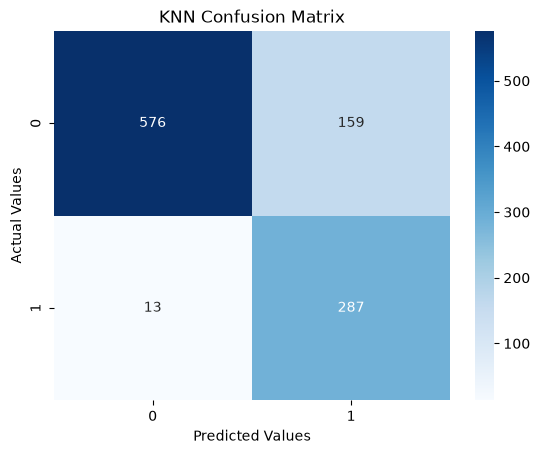

In [15]:
print("\nKNN PERFORMANCE")

knn_accuracy = accuracy_score(y_test, knn_pred)
knn_error = 1 - knn_accuracy
knn_precision = precision_score(y_test, knn_pred, zero_division=0)
knn_recall = recall_score(y_test, knn_pred, zero_division=0)
knn_f1 = f1_score(y_test, knn_pred, zero_division=0)

print("Accuracy:", knn_accuracy * 100, "%")
print("Error Rate:", knn_error * 100, "%")
print("Precision:", knn_precision * 100, "%")
print("Recall:", knn_recall * 100, "%")
print("F1 Score:", knn_f1 * 100, "%")

knn_cm = confusion_matrix(y_test, knn_pred)

print("\nKNN Confusion Matrix:")
print(knn_cm)

sns.heatmap(knn_cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("KNN Confusion Matrix")
plt.show()


SVM PERFORMANCE
Accuracy: 93.91304347826087 %
Error Rate: 6.086956521739129 %
Precision: 84.95575221238938 %
Recall: 96.0 %
F1 Score: 90.14084507042254 %

SVM Confusion Matrix:
[[684  51]
 [ 12 288]]


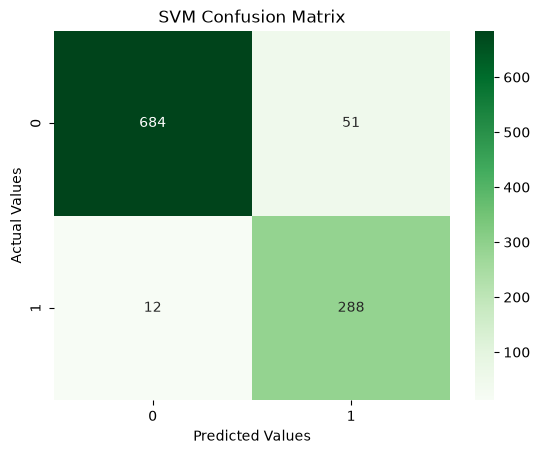

In [16]:
print("\nSVM PERFORMANCE")

svm_accuracy = accuracy_score(y_test, svm_pred)
svm_error = 1 - svm_accuracy
svm_precision = precision_score(y_test, svm_pred, zero_division=0)
svm_recall = recall_score(y_test, svm_pred, zero_division=0)
svm_f1 = f1_score(y_test, svm_pred, zero_division=0)

print("Accuracy:", svm_accuracy * 100, "%")
print("Error Rate:", svm_error * 100, "%")
print("Precision:", svm_precision * 100, "%")
print("Recall:", svm_recall * 100, "%")
print("F1 Score:", svm_f1 * 100, "%")

svm_cm = confusion_matrix(y_test, svm_pred)

print("\nSVM Confusion Matrix:")
print(svm_cm)

sns.heatmap(svm_cm, annot=True, fmt="d", cmap="Greens")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.title("SVM Confusion Matrix")
plt.show()


Performance Comparison:
  Algorithm  Accuracy  Error Rate  Precision  Recall  F1 Score
0       KNN     83.38       16.62      64.35   95.67     76.94
1       SVM     93.91        6.09      84.96   96.00     90.14


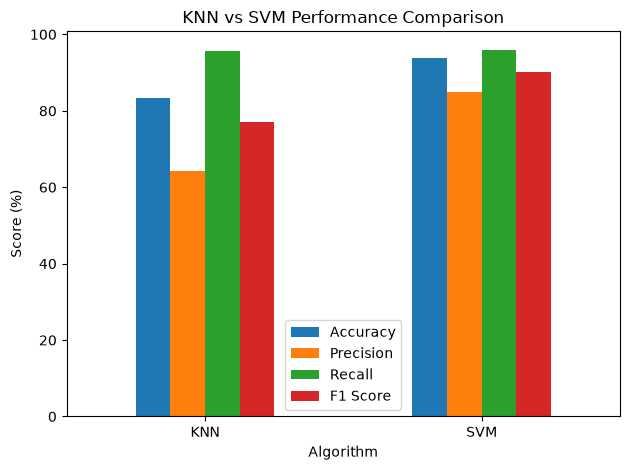

In [17]:
comparison = pd.DataFrame({
    "Algorithm": ["KNN", "SVM"],
    "Accuracy": [knn_accuracy * 100, svm_accuracy * 100],
    "Error Rate": [knn_error * 100, svm_error * 100],
    "Precision": [knn_precision * 100, svm_precision * 100],
    "Recall": [knn_recall * 100, svm_recall * 100],
    "F1 Score": [knn_f1 * 100, svm_f1 * 100]
})

print("\nPerformance Comparison:")
print(comparison.round(2))

comparison.plot(
    x="Algorithm",
    y=["Accuracy", "Precision", "Recall", "F1 Score"],
    kind="bar"
)

plt.ylabel("Score (%)")
plt.title("KNN vs SVM Performance Comparison")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [18]:
if knn_f1 > svm_f1:
    print("\nKNN performs better based on F1 Score.")

elif svm_f1 > knn_f1:
    print("\nSVM performs better based on F1 Score.")

else:
    print("\nBoth algorithms have equal F1 Score.")


SVM performs better based on F1 Score.
